# 03 · Transfer learning with feature extraction (Keras, CPU)

**Idea:** instead of training a CNN from scratch, a network pretrained on ImageNet (MobileNetV3-Small) is used as a feature extractor. Each image passes **only once** through the network, which remains frozen; the resulting vector (576 numbers per image) is saved and only a small head is trained on those vectors. Training the head takes seconds, so the full input resolution (224x224) can be used even without a GPU.

**Starting point (notebook 02):** the baseline without weights reached accuracy 0.803 and macro F1 0.746; with balanced `class_weight`, 0.758 and 0.723, that is, the full weights did not help in the aggregate. That is why two configurations are compared here: without weights (`CW_POWER=0`) and with soft weights (`CW_POWER=0.5`). The typical errors of the baseline were mites → `Target_Spot`, `Black_rot` ↔ `Esca` in grape, and confusions between different crops.

**Experiments:** four configurations were run (25% or 100% of train, with `CW_POWER` of 0 or 0.5). The outputs of this notebook (curves, per-class metrics, and confusions) correspond to the final configuration: **all of train and `CW_POWER=0.5`**. The table in section 9 compares all four.

**Limitation:** since the backbone is frozen and the features are computed only once, this version does not use data augmentation.

## 1. Setup

In [25]:
import os
import sys
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from src.data import load_splits
from src.features import build_backbone, extract_features

SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams["figure.dpi"] = 110
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Configuration

- `BACKBONE` and `IMG_SIZE`: pretrained network (MobileNetV3-Small; `efficientnetb0` is also supported) and input resolution (224x224).
- `BATCH_FEAT`: batch size when extracting features. `BATCH_HEAD` and `EPOCHS`: batch size and maximum number of epochs when training the head.
- `USE_SUBSET`: with `True`, the head is trained on the **same 25% of train that the baseline used** (same seed and stratification), for a fair comparison; with `False`, on all of train. Feature extraction is always done on the whole dataset, so this option does not change the extraction time.
- `CW_POWER`: exponent applied to the balanced class weights: `0` = no weights, `0.5` = soft weights, `1` = full balanced weights.
- Configuration of the results shown in this notebook: `USE_SUBSET=False` and `CW_POWER=0.5`.

In [26]:
BACKBONE = "mobilenetv3small"   # opctions: "mobilenetv3small" | "efficientnetb0"
IMG_SIZE = (224, 224)           # (width, height)
BATCH_FEAT = 64                 # batch for extracting features

USE_SUBSET = False              # True: same 25% of train as the baseline | False: all of train
SUBSET_FRACTION = 0.25
CW_POWER = 0.5                 # 0 = no weights | 0.5 = soft | 1 = balanced

EPOCHS = 40
BATCH_HEAD = 128

EXP_NAME = (
    f"tl_{BACKBONE}_{IMG_SIZE[0]}_cw{CW_POWER}"
    + ("_subset" if USE_SUBSET else "_full")
)
print("Experiment:", EXP_NAME)

Experiment: tl_mobilenetv3small_224_cw0.5_full


## 3. Data and backbone

The same splits as in the previous notebooks are loaded and MobileNetV3-Small pretrained on ImageNet is created, without its final classification layer and with global pooling: each image is summarized in a vector of 576 numbers. The backbone is kept frozen (its 939,120 parameters are not trained).

In [27]:
train, val, test = load_splits()

label_feat = train.features["label"]
id2name = dict(enumerate(label_feat.names))
n_classes = len(id2name)
names = [id2name[i] for i in range(n_classes)]
bg_id = [k for k, v in id2name.items() if v.startswith("Background")][0]
print("Classes:", n_classes, "| train/val/test:", len(train), len(val), len(test))

backbone = build_backbone(BACKBONE, IMG_SIZE)
backbone.trainable = False
print("Backbone:", backbone.name, "| params:", f"{backbone.count_params():,}",
      "| dim. de features:", backbone.output_shape[-1])

Classes: 39 | train/val/test: 38812 8317 8318
Backbone: MobileNetV3Small | params: 939,120 | dim. de features: 576


## 4. Feature extraction

This is the slow part of the notebook, but **it is done only once**: the result is saved in `data/cache/` and subsequent runs read it from disk (which is why the extraction time seen here is almost zero). During the first extraction, progress, images per second, and estimated remaining time are printed. If the process is interrupted, that extraction starts from scratch. The features are computed without data augmentation.

In [28]:
t0 = time.time()
X_train, y_train = extract_features(train, backbone, IMG_SIZE, name="train", batch_size=BATCH_FEAT)
X_val, y_val = extract_features(val, backbone, IMG_SIZE, name="val", batch_size=BATCH_FEAT)
X_test, y_test = extract_features(test, backbone, IMG_SIZE, name="test", batch_size=BATCH_FEAT)
print(f"Total extraction time: {(time.time() - t0) / 60:.1f} min")
print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

[cache] feat_train_MobileNetV3Small_38812_224x224.npz
[cache] feat_val_MobileNetV3Small_8317_224x224.npz
[cache] feat_test_MobileNetV3Small_8318_224x224.npz
Total extraction time: 0.0 min
train: (38812, 576) | val: (8317, 576) | test: (8318, 576)


In [29]:
if USE_SUBSET:
    idx = np.arange(len(y_train))
    keep, _ = train_test_split(
        idx, train_size=SUBSET_FRACTION, stratify=y_train, random_state=SEED
    )
    X_fit, y_fit = X_train[keep], y_train[keep]
    print("Head training (same subset as the baseline):", X_fit.shape)
else:
    X_fit, y_fit = X_train, y_train
    print("Head training (full):", X_fit.shape)

Head training (full): (38812, 576)


## 5. Class weights (optional)

scikit-learn's balanced weights are raised to the exponent `CW_POWER`. With `0.5` they are softened: small classes weigh less than with full balancing (here the weights range from 0.51 to 3.06; with `CW_POWER=1` they would range from about 0.26 to 9.4). With `CW_POWER=0` no weights are used

In [30]:
classes = np.arange(n_classes)
balanced = compute_class_weight("balanced", classes=classes, y=y_fit)
weights = balanced ** CW_POWER
class_weight = {int(c): float(w) for c, w in zip(classes, weights)} if CW_POWER > 0 else None
print("CW_POWER =", CW_POWER, "| min/max weight:", round(weights.min(), 2), "/", round(weights.max(), 2))

CW_POWER = 0.5 | min/max weight: 0.51 / 3.06


## 6. Classification head

It receives the vector of 576 features and normalizes it (with the mean and standard deviation of train); then it applies dropout of 0.2, a dense layer of 256 units with ReLU, dropout of 0.3, and a final layer of 39 outputs with softmax. It has 158,888 parameters (including those of the normalization), versus 103,191 for the baseline.

In [31]:
norm = layers.Normalization()
norm.adapt(X_fit)

def build_head(input_dim, n_classes):
    inputs = keras.Input(shape=(input_dim,))
    x = norm(inputs)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="head")

head = build_head(X_fit.shape[1], n_classes)
head.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
head.summary()

Model: "head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_2 (Normalization) │ (None, 576)            │         1,153 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 39)             │        10,023 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 158,888 (620.66 KB)

 Trainable params: 157,735 (616.15 KB)

 Non-trainable params: 1,153 (4.51 KB)

## 7. Head training

Adam optimizer (initial learning rate of 1e-3), batches of 128 and up to 40 epochs, with `EarlyStopping` (patience of 6 epochs on `val_loss`) and `ReduceLROnPlateau` (halves the learning rate if there is no improvement for 3 epochs). In the final configuration, training takes about 30 seconds and completes all 40 epochs: `EarlyStopping` was not triggered and `val_loss` was still decreasing slightly in the last epoch, so a higher maximum number of epochs could give a small improvement.

In [32]:
os.makedirs(os.path.join(ROOT, "models"), exist_ok=True)
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
]

t0 = time.time()
history = head.fit(
    X_fit, y_fit,
    validation_data=(X_val, y_val),
    batch_size=BATCH_HEAD,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=2,
)
train_time = time.time() - t0
print(f"Head training: {train_time:.0f} s")

Epoch 1/40
304/304 - 1s - 5ms/step - accuracy: 0.8408 - loss: 0.5926 - val_accuracy: 0.9585 - val_loss: 0.1349 - learning_rate: 0.0010
Epoch 2/40
304/304 - 1s - 2ms/step - accuracy: 0.9422 - loss: 0.1873 - val_accuracy: 0.9681 - val_loss: 0.0954 - learning_rate: 0.0010
Epoch 3/40
304/304 - 1s - 2ms/step - accuracy: 0.9558 - loss: 0.1349 - val_accuracy: 0.9751 - val_loss: 0.0768 - learning_rate: 0.0010
Epoch 4/40
304/304 - 1s - 2ms/step - accuracy: 0.9645 - loss: 0.1089 - val_accuracy: 0.9780 - val_loss: 0.0688 - learning_rate: 0.0010
Epoch 5/40
304/304 - 1s - 2ms/step - accuracy: 0.9694 - loss: 0.0936 - val_accuracy: 0.9781 - val_loss: 0.0652 - learning_rate: 0.0010
Epoch 6/40
304/304 - 1s - 2ms/step - accuracy: 0.9725 - loss: 0.0831 - val_accuracy: 0.9800 - val_loss: 0.0617 - learning_rate: 0.0010
Epoch 7/40
304/304 - 1s - 2ms/step - accuracy: 0.9745 - loss: 0.0751 - val_accuracy: 0.9779 - val_loss: 0.0679 - learning_rate: 0.0010
Epoch 8/40
304/304 - 1s - 2ms/step - accuracy: 0.9751 -

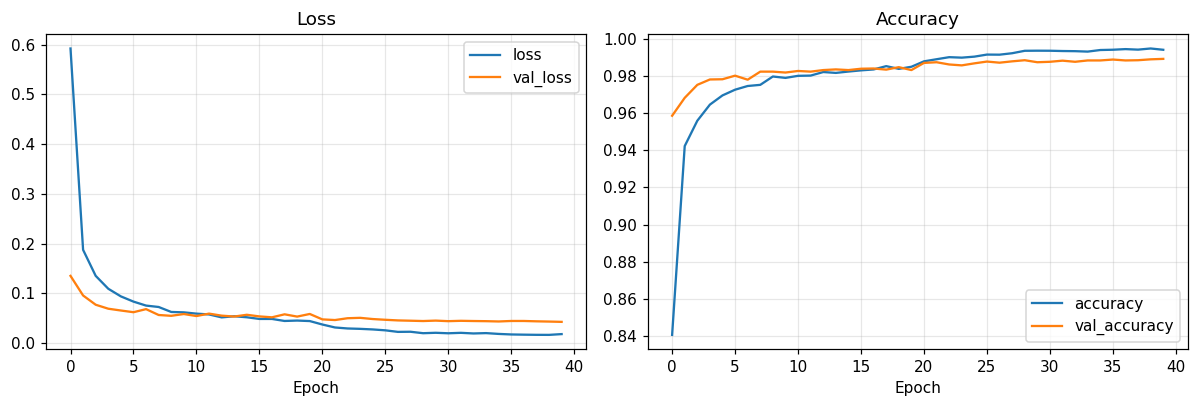

In [33]:
hist = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
hist[["loss", "val_loss"]].plot(ax=axes[0], title="Loss")
hist[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Evaluation on test

The metrics are the same as in the baseline: accuracy, macro F1 (main metric), and macro F1 without the background class. With the final configuration, the model reaches accuracy 0.987 and macro F1 0.982. Below are the ten classes with the worst F1 and the per-class F1 chart.

In [34]:
probs = head.predict(X_test, batch_size=256, verbose=0)
y_pred = probs.argmax(axis=1)

acc = float((y_pred == y_test).mean())
f1_macro = f1_score(y_test, y_pred, average="macro")
labels_no_bg = [c for c in range(n_classes) if c != bg_id]
f1_macro_no_bg = f1_score(y_test, y_pred, labels=labels_no_bg, average="macro")

print(f"Accuracy:                     {acc:.4f}")
print(f"F1 macro:                     {f1_macro:.4f}")
print(f"F1 macro (with no background class):   {f1_macro_no_bg:.4f}")

Accuracy:                     0.9870
F1 macro:                     0.9818
F1 macro (with no background class):   0.9815


In [35]:
report = classification_report(
    y_test, y_pred, labels=list(range(n_classes)),
    target_names=names, zero_division=0, output_dict=True,
)
df_rep = pd.DataFrame(report).T.iloc[:n_classes][["precision", "recall", "f1-score", "support"]]
df_rep.sort_values("f1-score").head(10).round(3)

,precision,recall,f1-score,support
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.905,0.870,0.887,77.0
Tomato___Target_Spot,0.947,0.924,0.935,211.0
Corn___Northern_Leaf_Blight,0.927,0.946,0.936,147.0
Potato___healthy,0.885,1.000,0.939,23.0
Tomato___Early_blight,0.965,0.920,0.942,150.0
Tomato___Spider_mites Two-spotted_spider_mite,0.938,0.960,0.949,252.0
Potato___Late_blight,0.967,0.967,0.967,150.0
Tomato___Leaf_Mold,0.965,0.972,0.969,143.0
Tomato___Late_blight,0.975,0.965,0.970,287.0
Tomato___Tomato_mosaic_virus,0.982,0.964,0.973,56.0


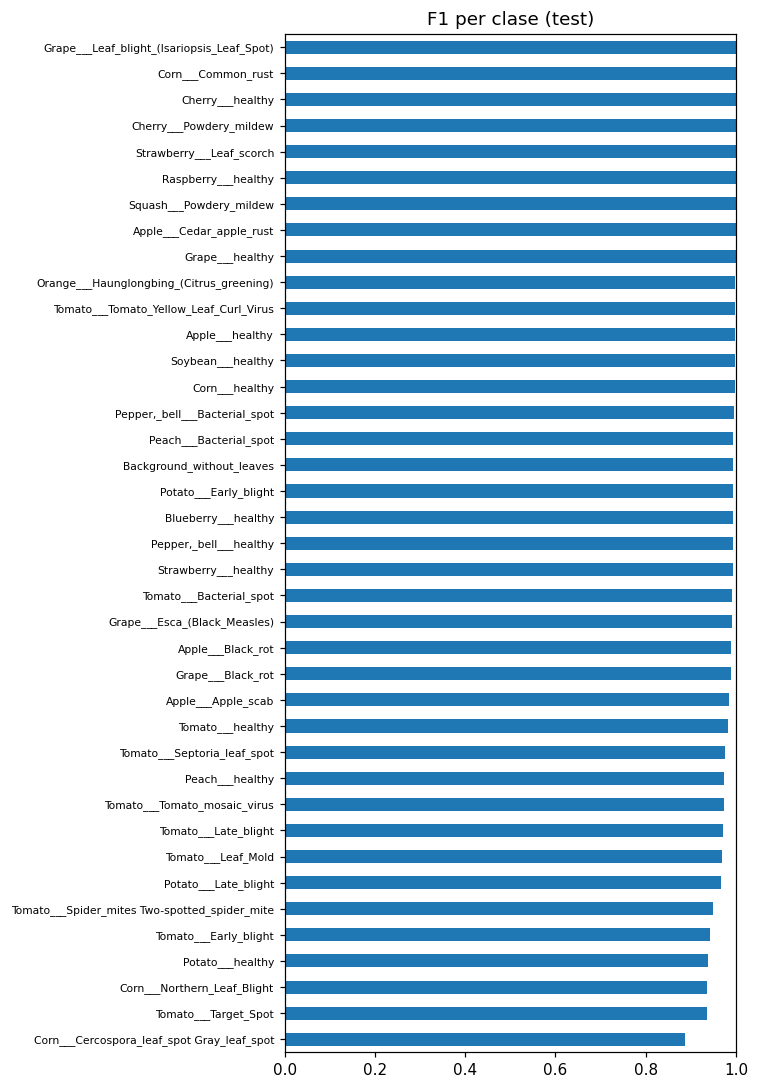

In [36]:
f1_by_class = df_rep["f1-score"].sort_values()
fig, ax = plt.subplots(figsize=(7, 10))
f1_by_class.plot.barh(ax=ax)
ax.set_xlim(0, 1)
ax.set_title("F1 per clase (test)")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### 8.1 Confusions

The table lists the 10 most frequent confusions (true class → predicted class) and the row-normalized confusion matrix shows the full picture: the diagonal is the proportion of correct predictions for each class and everything outside it is errors.

In [37]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(n_classes)))
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(off[i, j], names[i], names[j]) for i in range(n_classes) for j in range(n_classes) if off[i, j] > 0]
pairs.sort(reverse=True)
pd.DataFrame(pairs[:10], columns=["number", "real class", "predicted as"])

,number,real class,predicted as
0,10,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite
1,9,Corn___Cercospora_leaf_spot Gray_leaf_spot,Corn___Northern_Leaf_Blight
2,7,Corn___Northern_Leaf_Blight,Corn___Cercospora_leaf_spot Gray_leaf_spot
3,5,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot
4,5,Tomato___Late_blight,Potato___Late_blight
5,4,Tomato___Early_blight,Tomato___Septoria_leaf_spot
6,3,Tomato___Late_blight,Tomato___Early_blight
7,3,Peach___Bacterial_spot,Peach___healthy
8,2,Tomato___healthy,Tomato___Spider_mites Two-spotted_spider_mite
9,2,Tomato___Tomato_mosaic_virus,Tomato___Leaf_Mold


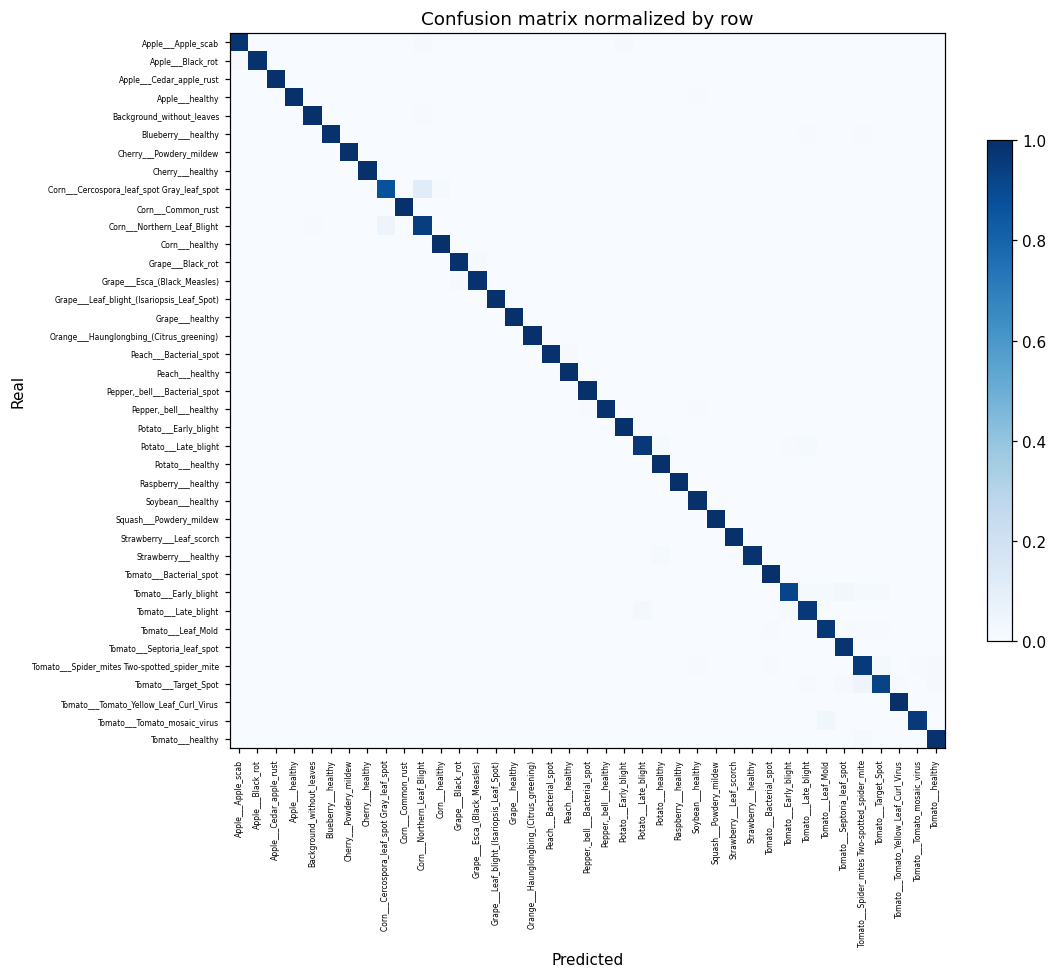

In [38]:
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_classes)); ax.set_yticks(range(n_classes))
ax.set_xticklabels(names, rotation=90, fontsize=5)
ax.set_yticklabels(names, fontsize=5)
ax.set_xlabel("Predicted"); ax.set_ylabel("Real")
ax.set_title("Confusion matrix normalized by row")
plt.colorbar(im, fraction=0.03)
plt.tight_layout()
plt.show()

## 9. Saving results and the full model

The experiment results are saved in `reports/` and an end-to-end model (image → backbone → head) in `models/`, which notebook 04 uses for Grad-CAM and the robustness test. The file is named `<experiment>_full.keras`; since the experiment name without a subset already ends in `_full`, the one for the final configuration ends up as `tl_mobilenetv3small_224_cw0.5_full_full.keras`. The final table compares the saved training experiments, including those from the baseline (notebook 02).

In [39]:
results = {
    "experiment": EXP_NAME,
    "img_size": list(IMG_SIZE),
    "subset": USE_SUBSET,
    "class_weight": CW_POWER > 0,
    "run_epochs": int(len(hist)),
    "training_time": round(train_time / 60, 1),
    "accuracy": round(acc, 4),
    "f1_macro": round(float(f1_macro), 4),
    "f1_macro_with_no_background": round(float(f1_macro_no_bg), 4),
    "params": int(head.count_params()),
}
out = os.path.join(ROOT, "reports", f"{EXP_NAME}.json")
with open(out, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("Saved in", out)

# Full model: image (0-255) -> backbone -> head
inp = keras.Input(shape=(IMG_SIZE[1], IMG_SIZE[0], 3))
full_model = keras.Model(inp, head(backbone(inp)), name=EXP_NAME)
full_model.save(os.path.join(ROOT, "models", f"{EXP_NAME}_full.keras"))
results

Saved in c:\Users\Carlos\Desktop\Python-Prep\proyecto_vision_plantvillage\reports\tl_mobilenetv3small_224_cw0.5_full.json


{'experiment': 'tl_mobilenetv3small_224_cw0.5_full',
 'img_size': [224, 224],
 'subset': False,
 'class_weight': True,
 'run_epochs': 40,
 'training_time': 0.5,
 'accuracy': 0.987,
 'f1_macro': 0.9818,
 'f1_macro_with_no_background': 0.9815,
 'params': 158888}

In [40]:
# Comparison of the training experiments saved in reports/
rows = []
for fn in sorted(os.listdir(os.path.join(ROOT, "reports"))):
    if fn.endswith(".json"):
        with open(os.path.join(ROOT, "reports", fn), encoding="utf-8") as f:
            r = json.load(f)
        if "experiment" in r:  # other reports, such as the robustness one, are omitted
            rows.append(r)
pd.DataFrame(rows).set_index("experiment")[
    ["subset", "class_weight", "accuracy", "f1_macro", "f1_macro_with_no_background", "training_minutes", "params"]
]

,subset,class_weight,accuracy,f1_macro,f1_macro_with_no_background,training_minutes,params
experiment,,,,,,,
baseline_nocw_128_subset,True,False,0.8033,0.7458,0.7426,17.6,103191
tl_mobilenetv3small_224_cw0.5_full,False,True,0.9870,0.9818,0.9815,NaN,158888


## 10. Conclusions

- **Improvement vs. baseline (same 25% of train):** macro F1 0.959 versus 0.746 for the baseline (0.960 with soft weights) and accuracy 0.968 versus 0.803. With the same amount of data, the worst class went from F1 0.37 to 0.80 (run without weights).
- **Time:** training the head takes between 6 and 30 seconds depending on the configuration, versus about 18 minutes for the baseline. Feature extraction is the slowest step, but it is done only once and stays cached.
- **Fit (final configuration):** train accuracy 0.994 versus 0.989 on validation. `val_loss` drops to 0.042 and was still improving slightly at epoch 40. There is no marked overfitting.
- **Persisting errors (final configuration):** the weakest classes are `Corn___Cercospora_leaf_spot` (F1 0.89), `Tomato___Target_Spot` (0.94), and `Corn___Northern_Leaf_Blight` (0.94). The most frequent confusions are `Target_Spot` → mites (10 cases) and `Cercospora` ↔ `Northern_Leaf_Blight` (9 and 7), almost all between similar diseases within tomato or corn. The confusions between different crops seen in the baseline no longer appear, except `Tomato___Late_blight` → `Potato___Late_blight` (5 cases), which is the same pathogen in two crops.
- **Background class:** the macro F1 without it (0.9815) is practically the same as the one that includes it (0.9818); it does not inflate the result.
- **Subset vs. full:** with all of train, macro F1 rises from 0.959 to 0.980 without weights (accuracy 0.968 → 0.985) and from 0.960 to 0.982 with soft weights. The data contribute more than any other change tested.
- **Class weights (`CW_POWER=0.5`):** +0.001 macro F1 with 25% of train and +0.002 with full train. Each configuration was run only once and the difference is probably within the noise, so it is not considered a real effect.
- **Best configuration:** frozen MobileNetV3-Small, 224x224, full train, and `CW_POWER=0.5`: accuracy 0.987 and macro F1 0.982.
- **Limitations:** no data augmentation (features are computed once), frozen backbone, split not grouped by leaf (metrics probably optimistic), a single run per configuration, and evaluation on images of the same type as the training ones (laboratory, uniform background).
- **Next step:** notebook 04 analyzes what the model focuses on with Grad-CAM and evaluates it on field images, which is the test of whether these results hold up outside the laboratory.